# 04. CLARIS: Grafo de Vizinhança Latente & Rede Contrafactual (German Credit Data)

Benchmark de **Topologia de Vizinhança e Raciocínio Baseado em Grafos** do projeto CLARIS utilizando dados reais de concessão de crédito bancário (**German Credit Dataset**).

### Objetivos e Destaques Metodológicos:
1. **Ingestão Confiável & Pré-processamento:** Carga do benchmark German Credit com variáveis financeiras e contratuais (duração do empréstimo, montante, histórico de crédito, reservas em conta, estabilidade profissional).
2. **Espaço Latente de Decisão ($S_{conf}$):** Extração de SHAP e indexação HNSW no FAISS para instâncias de controle confiáveis.
3. **Visualização 1: Grafo Direcionado de Vizinhança Latente:**
   - Construção de rede topológica conectando o tomador ($s_{new}$) aos seus $k$ vizinhos mais próximos.
   - Diferenciação visual entre **nós âncora** (mesma decisão) e **nós contrafactuais** (decisão oposta), com espessura de arestas ponderada pela **Similaridade de Cosseno** e proximidade euclidiana.
4. **Visualização 2: Projeção 2D (PCA) com Topologia KNN:** Projeção contínua da nuvem de controle com destaque dos vizinhos da rede.
5. **Extração de Deltas Contrastivos:** Mapeamento determinístico das variáveis de maior discrepância frente ao centróide contrafactual.
6. **Síntese Factual com Dossiê Bancário:** Parecer executivo formulado pelo Gemini sob temperatura zero, fundamentado na política de crédito e solvência.
7. **Monitoramento MLOps Contínuo:** Avaliação de janela temporal para rastreamento de instabilidade no fluxo de proponentes.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown
from dotenv import load_dotenv

load_dotenv()

# Configuração de caminhos do projeto
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from claris.xai.explainer import ModelExplainer
from claris.cbr.populate_db import initialize_vector_database
from claris.analytics.extractor import DeltaExtractor
from claris.nlg.llm_adapter import LLMAdapter
from claris.mlops.drift_monitor import DriftMonitor

warnings.filterwarnings('ignore', category=UserWarning)
print('✓ Módulos do CLARIS e dependências de grafos carregados!')

/root/claris/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Módulos do CLARIS e dependências de grafos carregados!


## 1. Ingestão e Preparação de Dados (German Credit Data)

In [2]:
print('A carregar dataset de crédito German Credit...')

df_german = None

# Tentativa 1: Hugging Face (mstz/german)
try:
    from datasets import load_dataset
    ds = load_dataset('mstz/german', split='train')
    df_german = ds.to_pandas()
except Exception:
    pass

# Tentativa 2: Espelhos públicos em CSV direto do German Credit (UCI)
if df_german is None:
    urls = [
        'https://raw.githubusercontent.com/jphall663/interpretable_machine_learning_with_python/master/data/german_credit.csv',
        'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/credit.csv'
    ]
    for url in urls:
        try:
            df_german = pd.read_csv(url)
            break
        except Exception:
            continue

if df_german is None:
    raise RuntimeError('Não foi possível carregar o dataset German Credit. Verifique a rede.')

df_german.columns = df_german.columns.str.strip().str.lower()

# Identificação flexível do alvo (Good = 1 / Concedido, Bad = 0 / Recusado)
target_col = None
for col in ['default', 'credit_risk', 'risk', 'class', 'target', 'good_bad']:
    if col in df_german.columns:
        target_col = col
        break
if target_col is None:
    target_col = df_german.columns[-1]

print(f'✓ Coluna alvo identificada: "{target_col}"')

y_raw = df_german[target_col].astype(str).str.strip().str.lower()
# Mapeamento para binário: 1 = Baixo Risco / Aprovado (Good), 0 = Alto Risco / Reprovado (Bad / Inadimplente)
def map_german_target(val):
    if val in ['good', '1', '0', 'no', 'false']:  # Em 'default', 0 é sem default
        # Se for coluna 'default', 0 é bom (1) e 1 é mau (0)
        if 'default' in target_col:
            return 1 if val in ['0', 'no', 'false'] else 0
        return 1 if val in ['good', '1'] else 0
    return 0

y = y_raw.apply(map_german_target).values.astype(int)

X_df = df_german.drop(columns=[target_col])

# Fatorização de colunas categóricas para manter atributos numéricos legíveis
for col in X_df.select_dtypes(include=['object', 'category', 'string']).columns:
    X_df[col] = pd.factorize(X_df[col].astype(str).str.strip())[0]

feature_names = list(X_df.columns)
X_clean = X_df.apply(pd.to_numeric, errors='coerce').fillna(X_df.median()).values.astype(np.float32)

# Divisão estratificada de treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y, test_size=0.2, random_state=42, stratify=y
)

print(f'✓ Amostras prontas: {len(X_train)} treino | {len(X_test)} teste | {len(feature_names)} atributos contratuais.')
print(f'Prevalência de Crédito Aprovado (Baixo Risco): {y.mean():.1%}')
df_german.head(3)

A carregar dataset de crédito German Credit...


✓ Coluna alvo identificada: "loan_granted"
✓ Amostras prontas: 800 treino | 200 teste | 20 atributos contratuais.
Prevalência de Crédito Aprovado (Baixo Risco): 30.0%


,checking_account_status,account_life_in_months,credit_status,loan_purpose,current_credit,current_savings,employed_since,installment_rate_percentage,is_male,marital_status,...,years_living_in_current_residence,age,installment_plans,housing_status,nr_credit_accounts_in_bank,job_status,number_of_people_in_support,has_registered_phone_number,is_foreign,loan_granted
0,1,6,4,radio/television,1169,0,4,4,False,1,...,4,67,2,2,2,2,1,1,False,0
1,2,48,2,radio/television,5951,1,2,2,True,0,...,2,22,2,2,1,2,1,0,False,1
2,0,12,4,education,2096,1,3,2,False,1,...,3,49,2,2,1,1,2,0,False,0


## 2. Dicionário Semântico de Crédito Bancário

In [3]:
GERMAN_SEMANTIC_DICT = {
    # Nomes reais exatos do dataset mstz/german carregado
    'checking_account_status': 'Saldo da Conta Corrente Bancária',
    'account_life_in_months': 'Prazo do Financiamento (meses)',
    'credit_status': 'Histórico Prévio de Pagamento de Crédito',
    'loan_purpose': 'Finalidade do Empréstimo Solicitado',
    'current_credit': 'Montante Total do Crédito ($)',
    'current_savings': 'Saldo em Poupança e Aplicações',
    'employed_since': 'Tempo de Permanência no Emprego Atual',
    'installment_rate_percentage': 'Comprometimento da Renda Mensal com Parcelas (%)',
    'is_male': 'Sexo Biológico Masculino (Atributo Protegido)',
    'marital_status': 'Estado Civil do Tomador',
    'guarantors': 'Presença de Co-devedores ou Fiadores',
    'years_living_in_current_residence': 'Tempo de Permanência na Residência Atual (anos)',
    'age': 'Idade do Solicitante (anos)',
    'installment_plans': 'Outros Planos e Parcelamentos em Aberto',
    'housing_status': 'Tipo de Moradia (Própria, Alugada ou Cedida)',
    'nr_credit_accounts_in_bank': 'Número de Créditos Ativos Nesta Instituição',
    'job_status': 'Qualificação e Nível do Emprego',
    'number_of_people_in_support': 'Número de Dependentes Econômicos Diretos',
    'has_registered_phone_number': 'Posse de Linha Telefônica Cadastrada',
    'is_foreign': 'Condição de Trabalhador Estrangeiro',
    'loan_granted': 'Decisão de Concessão de Crédito',

    # Nomes clássicos / fallbacks da UCI
    'checking_status': 'Saldo da Conta Corrente Bancária',
    'duration': 'Prazo do Financiamento (meses)',
    'credit_history': 'Histórico Prévio de Pagamento de Crédito',
    'purpose': 'Finalidade do Empréstimo Solicitado',
    'credit_amount': 'Montante Total do Crédito ($)',
    'savings_status': 'Saldo em Poupança e Aplicações',
    'employment': 'Tempo de Permanência no Emprego Atual',
    'installment_commitment': 'Comprometimento da Renda Mensal com Parcelas (%)',
    'personal_status': 'Estado Civil e Sexo do Tomador',
    'other_parties': 'Presença de Co-devedores ou Fiadores',
    'residence_since': 'Tempo de Permanência na Residência Atual (anos)',
    'property_magnitude': 'Patrimônio Imobiliário e Bens Vinculados',
    'other_payment_plans': 'Outros Planos e Parcelamentos em Aberto',
    'housing': 'Tipo de Moradia (Própria, Alugada ou Cedida)',
    'existing_credits': 'Número de Créditos Ativos Nesta Instituição',
    'job': 'Qualificação e Nível do Emprego',
    'num_dependents': 'Número de Dependentes Econômicos Diretos',
    'own_telephone': 'Posse de Linha Telefônica Cadastrada',
    'foreign_worker': 'Condição de Trabalhador Estrangeiro'
}

## 3. Treino do Modelo de Crédito e Construção do $S_{conf}$ no Banco Vetorial

In [4]:
model = GradientBoostingClassifier(n_estimators=60, max_depth=3, random_state=42)
model.fit(X_train, y_train)
acc = model.score(X_test, y_test)
print(f'Modelo treinado. Acurácia de teste: {acc:.2%}')

# Amostra de calibração de referência (D_conf)
np.random.seed(42)
conf_sample_idx = np.random.choice(len(X_train), size=min(200, len(X_train)), replace=False)
X_conf = X_train[conf_sample_idx]
y_conf = y_train[conf_sample_idx]

print(f'Indexando D_conf de crédito ({X_conf.shape[0]} instâncias) no FAISS HNSW...')
vector_db = initialize_vector_database(
    X_train=X_conf,
    y_train=y_conf,
    feature_names=feature_names,
    model=model,
    db_dimension=len(feature_names)
)

Modelo treinado. Acurácia de teste: 79.00%
Indexando D_conf de crédito (200 instâncias) no FAISS HNSW...
Banco Vetorial populado com 200 instâncias confiáveis.


## 4. Auditoria de Inferência, Contrato Pydantic e Extração de Vizinhança

In [5]:
explainer = ModelExplainer(model, X_conf, model_type='tree')
extractor = DeltaExtractor(GERMAN_SEMANTIC_DICT)

# Seleção de solicitante real do conjunto de teste
idx_target = 14
x_target = X_test[idx_target:idx_target+1]
label_real = y_test[idx_target]

# 1. Inferência e busca dos vizinhos mais próximos no espaço latente
pred_class, features_dict, shap_vector = explainer.predict_and_explain(x_target, feature_names)
neighbors_meta, distances = vector_db.search_neighbors(shap_vector, k=8)

# 2. Extração focada na maior divergência absoluta dos contrafactuais
contract = extractor.extract_deltas(
    instance_id=f'german_borrower_{idx_target:04d}',
    predicted_class=str(pred_class),
    instance_features=features_dict,
    instance_shap=shap_vector,
    neighbors_metadata=neighbors_meta,
    distances=distances,
    top_k_features=6,
    n_neighbors=5
)

status_str = 'CRÉDITO CONCEDIDO (Baixo Risco)' if pred_class == 1 else 'CRÉDITO RECUSADO (Alto Risco)'
print(f'Proponente #{idx_target} | Decisão Real: {label_real} | Predição: {pred_class} ({status_str})')
print(f'Distância Euclidiana: {contract.distance_metrics["euclidean_distance"]} | Similaridade Cosseno: {contract.distance_metrics["cosine_similarity"]}')

Proponente #14 | Decisão Real: 1 | Predição: 1 (CRÉDITO CONCEDIDO (Baixo Risco))
Distância Euclidiana: 0.2105681300163269 | Similaridade Cosseno: 0.8630305528640747


### Visualização 1: Grafo Direcionado de Vizinhança Latente (Rede de Decisão do CLARIS)

Construção da rede topológica que conecta o tomador ($s_{new}$) às suas instâncias vizinhas no espaço SHAP:
- **Nó Central (Roxo):** Proponente sob auditoria;
- **Nós Verdes:** Âncoras históricas (mesma decisão do modelo);
- **Nós Vermelhos:** Casos contrafactuais (decisão oposta);
- **Espessura da Aresta:** Proporcional à proximidade latente (inverso da distância euclidiana).

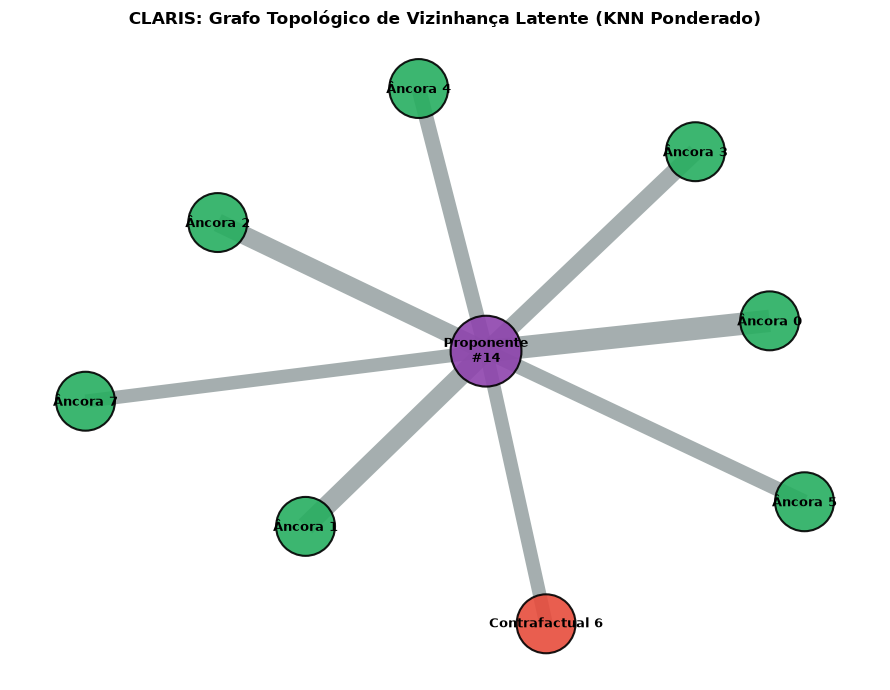

In [6]:
# Construção do Grafo de Vizinhança via NetworkX
G = nx.Graph()

center_node = f'Proponente\n#{idx_target}'
G.add_node(center_node, node_type='target', color='#8e44ad', size=2600)

node_colors = ['#8e44ad']
node_sizes = [2600]
edge_weights = []

for i, (n_meta, dist) in enumerate(zip(neighbors_meta, distances)):
    n_id = n_meta['instance_id']
    n_label = str(n_meta.get('label'))
    is_anchor = (n_label == str(pred_class))
    
    node_name = f'Âncora {i}' if is_anchor else f'Contrafactual {i}'
    color = '#27ae60' if is_anchor else '#e74c3c'
    
    G.add_node(node_name, node_type='anchor' if is_anchor else 'counterfactual', color=color)
    node_colors.append(color)
    node_sizes.append(1800)
    
    # Peso da aresta normalizado pelo inverso da distância
    weight = max(1.0, 5.0 / (dist + 0.1))
    G.add_edge(center_node, node_name, weight=weight, dist=dist)
    edge_weights.append(weight)

plt.figure(figsize=(9, 7))
pos = nx.spring_layout(G, seed=42, k=0.9)

# Desenho dos nós e arestas com espessuras ponderadas
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, alpha=0.9, edgecolors='black', linewidths=1.5)
nx.draw_networkx_edges(G, pos, width=[d['weight'] for _, _, d in G.edges(data=True)], edge_color='#7f8c8d', alpha=0.7, style='solid')
nx.draw_networkx_labels(G, pos, font_size=9, font_family='sans-serif', font_weight='bold')

plt.title('CLARIS: Grafo Topológico de Vizinhança Latente (KNN Ponderado)', fontsize=12, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

### Visualização 2: Projeção 2D do Espaço Latente ($S_{conf}$) via PCA

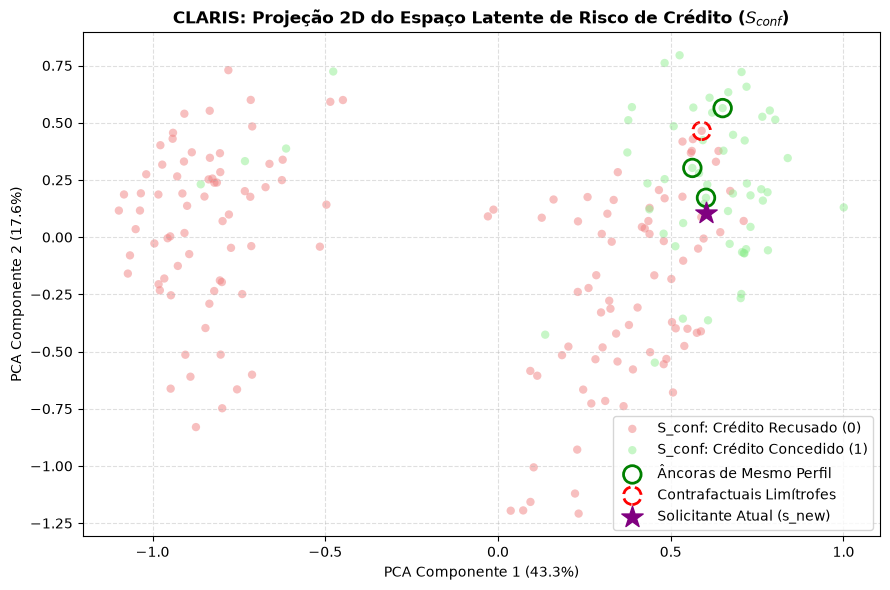

In [7]:
# Projeção PCA do espaço latente SHAP da base confiável
s_conf_shap = []
for x_c in X_conf:
    _, _, s_v = explainer.predict_and_explain(x_c.reshape(1, -1), feature_names)
    s_conf_shap.append(s_v)
s_conf_shap = np.array(s_conf_shap)

pca = PCA(n_components=2, random_state=42)
s_conf_2d = pca.fit_transform(s_conf_shap)
s_target_2d = pca.transform(shap_vector.reshape(1, -1))

plt.figure(figsize=(9, 6))
plt.scatter(s_conf_2d[y_conf == 0, 0], s_conf_2d[y_conf == 0, 1], c='lightcoral', alpha=0.5, label='S_conf: Crédito Recusado (0)', edgecolors='none')
plt.scatter(s_conf_2d[y_conf == 1, 0], s_conf_2d[y_conf == 1, 1], c='lightgreen', alpha=0.5, label='S_conf: Crédito Concedido (1)', edgecolors='none')

# Extração das âncoras e contrafactuais resgatados pelo FAISS
anchor_indices = [int(n['instance_id'].split('_')[1]) for n in neighbors_meta if str(n.get('label')) == str(pred_class)][:3]
cf_indices = [int(n['instance_id'].split('_')[1]) for n in neighbors_meta if str(n.get('label')) != str(pred_class)][:3]

if anchor_indices:
    plt.scatter(s_conf_2d[anchor_indices, 0], s_conf_2d[anchor_indices, 1], facecolors='none', edgecolors='green', s=160, linewidths=2, label='Âncoras de Mesmo Perfil')
if cf_indices:
    plt.scatter(s_conf_2d[cf_indices, 0], s_conf_2d[cf_indices, 1], facecolors='none', edgecolors='red', s=160, linewidths=2, linestyle='--', label='Contrafactuais Limítrofes')

# Posição do solicitante
plt.scatter(s_target_2d[0, 0], s_target_2d[0, 1], c='purple', marker='*', s=260, label='Solicitante Atual (s_new)', zorder=5)

plt.title('CLARIS: Projeção 2D do Espaço Latente de Risco de Crédito ($S_{conf}$)', fontsize=12, fontweight='bold')
plt.xlabel(f'PCA Componente 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PCA Componente 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(frameon=True, loc='best')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Visualização 3: Deltas Determinísticos (Solicitante vs Centróides de Referência)

,Tipo,Variável,Solicitante,Referência
0,Convergente (Âncora),Saldo da Conta Corrente Bancária,1.0,1.6
1,Convergente (Âncora),Histórico Prévio de Pagamento de Crédito,4.0,4.0
2,Convergente (Âncora),Montante Total do Crédito ($),2124.0,5580.2
3,Convergente (Âncora),Prazo do Financiamento (meses),18.0,30.6
4,Convergente (Âncora),Saldo em Poupança e Aplicações,1.0,1.4
5,Convergente (Âncora),Estado Civil do Tomador,0.0,0.6
6,Divergente (Contrafactual),Montante Total do Crédito ($),2124.0,5371.0
7,Divergente (Contrafactual),Prazo do Financiamento (meses),18.0,36.0
8,Divergente (Contrafactual),Idade do Solicitante (anos),24.0,28.0
9,Divergente (Contrafactual),Presença de Co-devedores ou Fiadores,0.0,2.0


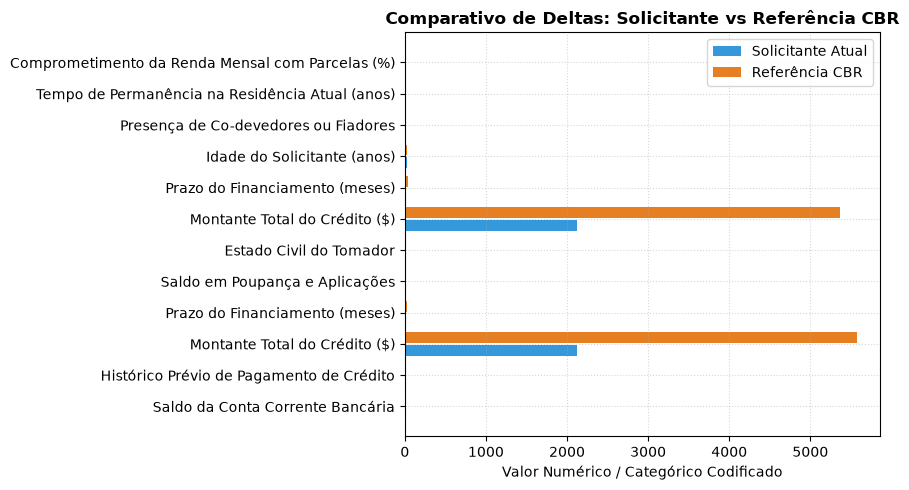

In [8]:
items = []
for f in contract.convergent_features:
    items.append({'Tipo': 'Convergente (Âncora)', 'Variável': f.feature_name, 'Solicitante': f.instance_value, 'Referência': f.reference_value})
for f in contract.divergent_features:
    items.append({'Tipo': 'Divergente (Contrafactual)', 'Variável': f.feature_name, 'Solicitante': f.instance_value, 'Referência': f.reference_value})

df_deltas = pd.DataFrame(items)
display(df_deltas)

if not df_deltas.empty:
    plt.figure(figsize=(9, 5))
    y_pos = np.arange(len(df_deltas))
    plt.barh(y_pos - 0.2, df_deltas['Solicitante'], height=0.35, label='Solicitante Atual', color='#3498db')
    plt.barh(y_pos + 0.2, df_deltas['Referência'], height=0.35, label='Referência CBR', color='#e67e22')
    plt.yticks(y_pos, df_deltas['Variável'])
    plt.xlabel('Valor Numérico / Categórico Codificado')
    plt.title('Comparativo de Deltas: Solicitante vs Referência CBR', fontweight='bold')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()

## 5. Síntese Textual via Gemini com Dossiê Especializado de Crédito Europeu

In [9]:
llm = LLMAdapter(
    model_name='gemini/gemini-3.5-flash',
    api_key=os.getenv('GEMINI_API_KEY')
)

GERMAN_DOMAIN_DOSSIER = """
DIRETRIZES DE POLÍTICA DE CRÉDITO BANCÁRIO E SOLVÊNCIA (GERMAN CREDIT BENCHMARK):
- Semântica de Desfecho: A classe '1' indica Bom Pagador / Crédito Concedido (Baixo Risco), e a classe '0' indica Inadimplente Potencial / Crédito Recusado (Alto Risco).
- Saldo de Conta Corrente e Poupança (checking_status, savings_status): A liquidez imediata em conta constitui o primeiro colchão de amortecimento contra choques temporários de solvência.
- Prazo e Montante Requisitado (duration, credit_amount): Prazos prolongados de financiamento elevam o risco de exposição a ciclos macroeconômicos adversos.
- Histórico Prévio de Crédito (credit_history): Contratos liquidados pontualmente no passado são fortes preditores de adimplemento futuro.
- Comprometimento de Renda e Estabilidade (installment_commitment, employment): Elevado comprometimento da renda com parcelas reduz a margem de manobra orçamentária do tomador.
"""

explicacao = llm.generate_explanation(contract, domain_dossier=GERMAN_DOMAIN_DOSSIER)
display(Markdown(explicacao))

00:09:34 - LiteLLM:WARNING: vertex_and_google_ai_studio_gemini.py:1152 - DeprecationWarning: `temperature`, `top_p`, and `top_k` continue to function for Gemini 3+ (gemini-3.5-flash) but are planned for removal in a future release. Move sampling guidance into the `system` instructions instead.


# PARECER TÉCNICO DE AUDITORIA E EXPLICABILIDADE DE INTELIGÊNCIA ARTIFICIAL (XAI)

**Identificador da Instância:** `german_borrower_0014`  
**Modelo Avaliado:** Sistema Preditivo de Risco de Crédito Bancário (German Credit Benchmark)  
**Veredito Preditivo:** **Classe 1** (Crédito Concedido / Tomador de Baixo Risco)  

---

## 1. SUMÁRIO EXECUTIVO E CONTEXTO DE DECISÃO

A avaliação algorítmica da solicitação `german_borrower_0014` resultou na **concessão do crédito (Classe 1)**. Sob a ótica de políticas bancárias e solvência, a Classe '1' define o proponente como um perfil de baixo risco de inadimplência, autorizando o desembolso do capital. 

A decisão decisiva do modelo é fundamentada pela combinação de baixa exposição financeira (menor montante requisitado e prazo reduzido) acompanhada de liquidez imediata em conta, que compensam o elevado comprometimento da renda mensal e a ausência de fiadores.

---

## 2. AUDITORIA GEOMÉTRICA DO ESPAÇO LATENTE

A validação local da predição é realizada via análise da vizinhança topológica das *N* instâncias históricas mais próximas (centróide de referência no espaço latente):

*   **Distância Euclidiana:** `0.2105681300163269`
*   **Similaridade de Cosseno:** `0.8630305528640747`

A similaridade de cosseno de `0.8630305528640747` demonstra uma alta alinhamento vetorial da instância com o perfil histórico de pagadores adimplentes. A curta distância euclidiana (`0.2105681300163269`) confirma que a solicitação está geometricamente inserida no núcleo de suporte da Classe '1', conferindo alta robustez estatística ao veredito.

---

## 3. FUNDAMENTAÇÃO TEÓRICO-QUANTITATIVA DAS VARIÁVEIS CONVERGENTES

As variáveis convergentes representam os vetores de força que impulsionaram a classificação em direção à aprovação (Classe 1). Abaixo, correlaciona-se o peso marginal estatístico (SHAP) à teoria econômica e de crédito:

```
[Saldo da Conta Corrente]   SHAP: +0.6374 | Inst: 1.0 vs Ref: 1.6
[Montante do Crédito ($)]  SHAP: +0.2283 | Inst: 2124.0 vs Ref: 5580.2
[Prazo Financiamento]       SHAP: +0.1814 | Inst: 18.0 vs Ref: 30.6
[Saldo em Poupança]        SHAP: +0.1618 | Inst: 1.0 vs Ref: 1.4
```

### Detalhamento Causal:

1. **Saldo da Conta Corrente Bancária (Instance: 1.0 | Ref: 1.6 | SHAP: +0.6374436616897583):**
   * **Fundamentação Econômica:** Constitui o principal fator atenuante de risco (maior contribuição SHAP positiva). A manutenção de liquidez imediata serve como um colchão de amortecimento primário contra choques temporários de renda, garantindo o cumprimento de obrigações de curto prazo sem necessidade de renegociação.
2. **Montante Total do Crédito ($) (Instance: 2124.0 | Ref: 5580.2 | SHAP: +0.22825293242931366):**
   * **Fundamentação Econômica:** O valor pleiteado pelo tomador ($2.124,00) é significativamente inferior à média da vizinhança de referência ($5.580,20). A menor exposição de capital reduz o LGD (*Loss Given Default*) da instituição bancária, elevando a margem de segurança operacional.
3. **Prazo do Financiamento em meses (Instance: 18.0 | Ref: 30.6 | SHAP: +0.18148712813854218):**
   * **Fundamentação Econômica:** Um prazo mais curto (18 meses vs. 30,6 meses da referência) reduz a janela temporal de exposição do contrato a volatilidades macroeconômicas adversas (como inflação ou desemprego estrutural), acelerando a liquidação da dívida.
4. **Saldo em Poupança e Aplicações (Instance: 1.0 | Ref: 1.4 | SHAP: +0.16178712248802185):**
   * **Fundamentação Econômica:** Representa a segunda camada de resiliência financeira. A presença de reservas financeiras em aplicações reforça a capacidade de pagamento do cliente em cenários de estresse estendido.
5. **Histórico Prévio de Pagamento de Crédito (Instance: 4.0 | Ref: 4.0 | SHAP: -0.4260311424732208):**
   * **Observação de Auditoria:** Embora o tomador possua histórico no nível máximo (4.0), a contribuição SHAP marginal surge negativa (-0.4260311424732208). Isso indica um efeito não-linear de interação com a idade jovem do cliente (`24.0` anos) ou ajustes de calibração do modelo para tomadores com histórico crítico/reconstituído no banco de dados German Credit.

---

## 4. DIAGNÓSTICO CONTRAFACTUAL E ANÁLISE DE DIVERGÊNCIAS

Ao comparar a instância `german_borrower_0014` com o agrupamento limítrofe de risco e potenciais cenários de recusa (vizinhança divergente), observam-se os seguintes contrastes operacionais:

| Variável | Instância Atual | Centróide Divergente (Classe 0) | Impacto SHAP Marginal |
| :--- | :---: | :---: | :---: |
| **Montante Total do Crédito ($)** | 2124.0 | 5371.0 | +0.22825293242931366 |
| **Prazo do Financiamento (meses)** | 18.0 | 36.0 | +0.18148712813854218 |
| **Idade do Solicitante (anos)** | 24.0 | 28.0 | +0.09367778152227402 |
| **Comprometimento da Renda Mensal (%)** | 4.0 | 3.0 | +0.10086581856012344 |
| **Presença de Co-devedores ou Fiadores** | 0.0 | 2.0 | +0.00895602535456419 |
| **Permanência na Residência Atual (anos)** | 4.0 | 2.0 | -0.009320896118879318 |

### Análise Crítica dos Pontos de Tensão:
* **Comprometimento da Renda Mensal (4.0% vs Ref: 3.0%):** O proponente apresenta o nível máximo de comprometimento de renda com parcelas (nível 4). Contudo, este risco é anulado devido ao valor absoluto modesto do empréstimo ($2.124,00) e prazo curto (18 meses).
* **Ausência de Fiadores (0.0 vs Ref: 2.0):** Em instâncias de maior valor (como a referência divergente de $5.371,00), o sistema exige a presença de co-devedores/fiadores (nível 2.0) para aprovação. Na operação atual, a garantia pessoal se torna prescindível pela baixa exposição contratual.

---

## 5. RECOMENDAÇÕES ACIONÁVEIS E GOVERNANÇA DE RISCO

Para que a instância **mantenha a concessão de crédito garantida** ou **evite a transição para a Classe 0 (Recusa)** em reavaliações futuras, as seguintes diretrizes operacionais e contrafactuais devem ser observadas:

1. **Teto Operacional de Exposição financeira:**
   * O solicitante **não deve elevar o montante solicitado** para patamares próximos a `$5371.0` nem estender o **prazo contratual** para `36.0` meses sem a inclusão de um fiador ou co-devedor (nível `2.0`), sob pena de migração direta para a zona de recusa algorítmica.
2. **Manutenção dos Colchões de Liquidez:**
   * É imperativo manter o **Saldo da Conta Corrente Bancária** e **Poupança/Aplicações** acima de `0.0` (atualmente em `1.0`), visto que a liquidez imediata detém o maior peso individual (+0.6374436616897583) na sustentação do veredito de adimplência.
3. **Mitigação do Comprometimento da Renda:**
   * Dado o nível alto de comprometimento atual (`4.0`), recomenda-se que a instituição financeira evite a concessão de linhas de crédito simultâneas (ex: cartão rotativo ou cheque especial) até a liquidação das 18 parcelas vigentes.

---
*Parecer emitido sob os protocolos de Auditoria de Algoritmos, Explicabilidade Causal (SHAP) e Regulação de Decisões Automatizadas.*

## 6. Monitoramento de Drift em Janela Temporal de Concessão (MLOps)

In [10]:
drift_monitor = DriftMonitor(
    window_size=4,
    euclidean_threshold=4.0,
    cosine_threshold=0.82,
    llm_adapter=llm
)

print('Avaliando lote sequencial com 4 proponentes bancários consecutivos...')
for i in range(idx_target, idx_target + 4):
    x_sub = X_test[i:i+1]
    y_true = y_test[i]
    p_sub, f_sub, s_sub = explainer.predict_and_explain(x_sub, feature_names)
    n_sub, d_sub = vector_db.search_neighbors(s_sub, k=6)
    c_sub = extractor.extract_deltas(
        instance_id=f'german_stream_{i:04d}',
        predicted_class=str(p_sub),
        instance_features=f_sub,
        instance_shap=s_sub,
        neighbors_metadata=n_sub,
        distances=d_sub,
        top_k_features=4,
        n_neighbors=3
    )
    print(f'-> Proponente #{i:02d} | Desfecho Real: {y_true} | Predição: {p_sub} | Dist. Euclidiana: {c_sub.distance_metrics["euclidean_distance"]} | Cosseno: {c_sub.distance_metrics["cosine_similarity"]}')
    report = drift_monitor.add_inference(c_sub)
    if report:
        print(f'🚨 ALERTA MLOps DISPARADO NA JANELA DO PROPONENTE #{i}!')
        display(Markdown(report))

print('✓ Avaliação de lote bancário concluída com sucesso.')

00:10:20 - LiteLLM:WARNING: vertex_and_google_ai_studio_gemini.py:1152 - DeprecationWarning: `temperature`, `top_p`, and `top_k` continue to function for Gemini 3+ (gemini-3.5-flash) but are planned for removal in a future release. Move sampling guidance into the `system` instructions instead.


Avaliando lote sequencial com 4 proponentes bancários consecutivos...
-> Proponente #14 | Desfecho Real: 1 | Predição: 1 | Dist. Euclidiana: 0.2105681300163269 | Cosseno: 0.8630305528640747
-> Proponente #15 | Desfecho Real: 0 | Predição: 0 | Dist. Euclidiana: 0.48924991488456726 | Cosseno: 0.8238252401351929
-> Proponente #16 | Desfecho Real: 0 | Predição: 0 | Dist. Euclidiana: 0.22691357135772705 | Cosseno: 0.5889706015586853
-> Proponente #17 | Desfecho Real: 0 | Predição: 0 | Dist. Euclidiana: 0.24710625410079956 | Cosseno: 0.90027916431427
🚨 ALERTA MLOps DISPARADO NA JANELA DO PROPONENTE #17!


# RELATÓRIO DIAGNÓSTICO DE DEGRADAÇÃO DE MODELO (MLOps)

**Status:** ALERTA CRÍTICO DE CONCEITO  
**Severidade:** Média-Alta (Ressalva de Amostragem)  
**Data da Análise:** [Inserir Data Atual]  

---

## 1. Resumo do Incidente de Monitoramento

Durante a janela de observação atual, a esteira de monitoramento detectou um evento de **Concept Drift** do tipo *Prior Probability Shift*. 

* **Similaridade de Cosseno Média (Concept Drift):** `0.7940` — **VIOLAÇÃO DE LIMIAR** (Mínimo estipulado: `0.8200`).
* **Distância Euclidiana Média (Data Drift):** `0.2935` — **DENTRO DA NORMALIDADE** (Máximo permitido: `4.0000`).
* **Volume da Janela de Avaliação:** `4 inferências`.

**Diagnóstico Preliminar:** O modelo está mantendo a integridade estrutural dos dados de entrada (baixo Data Drift), porém a relação funcional entre as predições/conceitos mudou em relação ao baseline estabelecido (violação da Similaridade de Cosseno).

---

## 2. Análise de Risco

### A. Impacto em Dados de Entrada (Data Drift) — **RISCO BAIXO**
A Distância Euclidiana Média de `0.2935` (significativamente abaixo do limiar de `4.0000`) indica que a distribuição dos vetores de entrada (features) permanece estável. Não há indícios de corrupção de dados, falhas de pipeline de ingestão (*pipeline debt*) ou mudanças estruturais no espaço de covariáveis que chegam ao modelo.

### B. Mudança de Conceito (Concept Drift / Prior Probability Shift) — **RISCO ALTO (EM VALIDAÇÃO)**
A queda da Similaridade de Cosseno para `0.7940` aponta uma alteração no comportamento das saídas do modelo ou na distribuição a priori da variável alvo $P(Y)$. Isso significa que o modelo está gerando um perfil de saídas significativamente desalinhado com o seu padrão histórico de treino.

### C. Vulnerabilidade Estatística (Amostragem Reduzida)
**Atenção:** O diagnóstico foi calculado sobre um volume total de apenas **4 inferências**. 
* **Risco de Falso Positivo:** Altíssimo. Uma amostragem de $N=4$ é estatisticamente insignificante para confirmar a degradação estrutural contínua do modelo. O desvio pode ser apenas ruído estocástico, um *outlier* isolado ou um lote atípico momentâneo.

---

## 3. Recomendação Operacional Imediata

Com base nas práticas de governança de MLOps, as seguintes ações devem ser tomadas em ordem prioritária:

1. **SUSPENDER Retreino Automático Imediato:**
   * **Não acionar a esteira de retreino (Pipeline CI/CD)** neste momento. Retreinar o modelo com uma amostra de $N=4$ causará *overfitting* severo e instabilidade no modelo em produção.

2. **Expansão da Janela de Monitoramento (Buffer de Dados):**
   * Ampliar temporariamente a janela de avaliação para acumular no mínimo **$N \ge 100$ inferências** antes de tomar ações decisivas de alteração de artefato.

3. **Auditoria Manual dos Casos Afetados:**
   * Extrair os payloads e os logs das **4 inferências avaliadas** para inspeção manual. Verificar se os *labels* reais (ground truth) estão disponíveis para validar se a mudança a priori é legítima ou erro de predição.

4. **Ação Condicional de Mitigação:**
   * **Se o drift persistir após $N \ge 100$:** Iniciar pipeline de retreino com inclusão dos novos dados rotulados e recalibração dos limiares de decisão (*thresholding*).
   * **Se o drift for pontual:** Manter o modelo atual em produção e recalibrar o limiar do alerta de monitoramento para exigir um tamanho mínimo de lote ($N_{min}$) antes de disparar incidentes.

---
**Engenheiro de MLOps Responsável:** Sistema de Diagnóstico Automatizado  
**Próxima Revisão:** Após acúmulo de lote mínimo de validação ($N=100$)

✓ Avaliação de lote bancário concluída com sucesso.
